<a href="https://colab.research.google.com/github/bvsvntv/ai-ml-learning/blob/main/notebooks/lang-graph/basic_hitl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -U langchain-openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 587.1/587.1 kB 7.1 MB/s  0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langchain-openai]


In [10]:
from langchain_openai import ChatOpenAI
from langchain_core.messages import AnyMessage, AIMessage, BaseMessage

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command
from typing import TypedDict, Annotated
from google.colab import userdata

from IPython.display import Image

In [5]:
api_key = userdata.get("OPENAI_API_KEY")
llm = ChatOpenAI(api_key=api_key, model="gpt-6-luna")

In [6]:
class ChatState(TypedDict):
  messages: Annotated[list[BaseMessage], add_messages]

In [32]:
def chat_node(state: ChatState):
  decision = interrupt({
      "type": "approval",
      "reason": "Model is about to answer a user question.",
      "question": state["messages"][-1].content,
      "instruction": "Approve this question? yes/no"
  })

  if decision == "no":
    return {"messages": [AIMessage(content="Not approved.")]}
  else:
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

In [33]:
builder = StateGraph(ChatState)

builder.add_node("chat", chat_node)

builder.add_edge(START, "chat")
builder.add_edge("chat", END)

checkpointer = MemorySaver()

app = builder.compile(checkpointer=checkpointer)

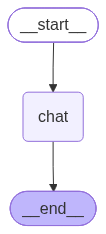

In [13]:
# view graph
Image(app.get_graph().draw_mermaid_png())

In [34]:
config = {"configurable": {"thread_id": 1}}

initial_input = {
    "messages": [
        ("user", "Explain HITL in simple terms.")
    ]
}

result = app.invoke(initial_input, config=config)

In [35]:
print(result)

{'messages': [HumanMessage(content='Explain HITL in simple terms.', additional_kwargs={}, response_metadata={}, id='37eb1e76-a999-4b48-8a11-c0c74db822ef')], '__interrupt__': [Interrupt(value={'type': 'approval', 'reason': 'Model is about to answer a user question.', 'question': 'Explain HITL in simple terms.', 'instruction': 'Approve this question? yes/no'}, id='a7ac5afcea4160a56a9b9ce0fbe33008', response_schema=None)]}


In [36]:
prompt = result['__interrupt__'][0].value

print(prompt)

{'type': 'approval', 'reason': 'Model is about to answer a user question.', 'question': 'Explain HITL in simple terms.', 'instruction': 'Approve this question? yes/no'}


In [37]:
user_input = input(f"Backend message - {prompt} \n Approve this question? (y/n)")

Backend message - {'type': 'approval', 'reason': 'Model is about to answer a user question.', 'question': 'Explain HITL in simple terms.', 'instruction': 'Approve this question? yes/no'} 
 Approve this question? (y/n)yes


In [38]:
# resume the graph with the approval decision
final_result = app.invoke(
    Command(resume={"approved": user_input}),
    config=config
)

In [39]:
print(final_result["messages"][-1].content)

**HITL** means **“human in the loop.”** It’s when a person checks or guides an automated system instead of letting it make every decision on its own.

For example, an AI might flag a loan application as risky, but a human reviews it before deciding whether to approve or reject it.
